# 第5章练习（三）：把聚类结果当作特征交给随机森林

[ch5_meta_labeling2.ipynb](ch5_meta_labeling2.ipynb) 证明了混合样本里确实存在结构性代价，
但它用的办法是把资产池缩到一个簇——换来同质性的代价是训练事件减少 84%，meta-labeling 直接反向失效。

本 Notebook 换一条路：**不缩池，把簇标签当作一行额外的列交给随机森林**，
让模型自己决定「同一组特征在不同簇里该读出什么」。

要回答三个问题：

1. 聚类信息该以什么形式进入模型——整数编码、独热、簇画像，还是簇内标准化？
2. 它是否真的把「用波动率识别资产类别」的隐式捷径，变成「按簇条件分裂」的显式路径？
3. (a)–(e) 全链路在保留全部样本量的前提下是否仍然成立？

## 统一实验约定

数据口径、三重障碍参数、成本与 Sharpe 聚合方式与 [ch5_meta_labeling.ipynb](ch5_meta_labeling.ipynb) 完全一致：
最近 1,260 个价格观测，前 1,008 个训练、后 252 个测试，固定种子 42。

簇标签取自 [cluster_membership_denoise.csv](cluster_membership_denoise.csv) 的「层次聚类」列，
资产顺序已与实验资产池逐一对齐（代码中带断言）。

**这一点必须说清楚**：该文件由 [ch4_optimal_clustering.ipynb](ch4_optimal_clustering.ipynb) 生成，
聚类的输入是 `data.X_train`，即前 1,007 个**训练期**收益，完全不包含 252 个测试期价格。
所以把簇标签当特征使用不构成测试期前视。第 3 节会再验证它在训练期内是否漂移。

**与上一本唯一的区别**：训练与回测仍然使用全部 488 只基金，只是特征矩阵里多了簇的信息。

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, adjusted_rand_score,
                             normalized_mutual_info_score)
from skfolio.moments import DenoiseCovariance, DetoneCovariance
from skfolio.cluster import HierarchicalClustering
from skfolio.utils.stats import cov_to_corr
from IPython.display import display
from notebook_common import load_data, setup_notebook, timed

SEED = 42
setup_notebook(SEED)
data = load_data()
prices, assets = data.prices, list(data.assets)
display(data.summary())

X_train = data.X_train
print(f'训练收益 {X_train.shape}：{X_train.index[0].date()} 至 {X_train.index[-1].date()}（聚类只用到这段）')
print(f'测试收益 {data.X_test.shape}：{data.X_test.index[0].date()} 至 {data.X_test.index[-1].date()}（聚类未接触）')

数据模式                          全部合格基金
每侧缩尾比例                         0.00%
训练期合格基金数                         488
本次使用基金数                          488
训练收益行数                          1007
训练收益区间       2021-07-14 至 2025-09-04
测试候选区间       2025-09-05 至 2026-09-18
测试候选日期数                          252
测试共同有效日期数                        252
排除测试日期数                            0
测试日期覆盖率                      100.00%
Name: 数据概览, dtype: object

训练收益 (1007, 488)：2021-07-14 至 2025-09-04（聚类只用到这段）
测试收益 (252, 488)：2025-09-05 至 2026-09-18（聚类未接触）


## 1. 聚类信息进入模型的四种方式

把「簇」交给随机森林，至少有四条路，它们携带的信息与风险都不同：

| 编码 | 形式 | 模型能做什么 | 代价 |
| --- | --- | --- | --- |
| 整数编码 | 单列 0–11 | 在簇号上做阈值分裂 | 簇号本无大小含义，得多切几刀才能分离 |
| 独热 | 12 列 0/1 | 每个簇一套独立的分裂路径 | 维度上升，小簇分支易过拟合 |
| 簇画像 | 簇内平均相关、波动中位、规模占比 | 按「这个簇有多同质」分裂，而非「它是几号」 | 只有 3 列，区分粒度有限 |
| 簇内标准化 | 8 个特征的簇内 z 值 | 消掉跨簇方差，只看「相对同簇其他人」 | 丢弃了簇间的绝对水平 |

前两种显式告诉模型「你在哪个簇」，后两种把聚类结果折算成连续变量。
保留全部 48.5 万条训练事件是这套做法的全部好处——不像单簇版那样砍到 7.9 万。

In [2]:
membership = pd.read_csv('cluster_membership_denoise.csv').set_index('Unnamed: 0')
assert list(membership.index) == assets, '簇成员必须先与实验资产池逐一对齐'
cluster = membership['层次聚类'].astype(int)

corr_train = X_train.corr()
within = {}
for cid in sorted(cluster.unique()):
    ids = cluster[cluster == cid].index
    block = corr_train.loc[ids, ids].to_numpy()
    within[cid] = block[np.triu_indices(len(ids), 1)].mean()

annual_vol = X_train.std() * np.sqrt(252)
profile = pd.DataFrame({
    '规模': cluster.value_counts().sort_index(),
    '占比': cluster.value_counts(normalize=True).sort_index(),
    '年化波动中位': annual_vol.groupby(cluster).median(),
    '偏度中位': X_train.skew().groupby(cluster).median(),
    '峰度中位': X_train.kurt().groupby(cluster).median(),
    '簇内平均相关': pd.Series(within),
})
display(profile.round(4))
print(f'共 {cluster.nunique()} 个簇，规模 {profile["规模"].min()}～{profile["规模"].max()} 只；'
      f'簇内平均相关横跨 {profile["簇内平均相关"].min():.3f}～{profile["簇内平均相关"].max():.3f}')

,规模,占比,年化波动中位,偏度中位,峰度中位,簇内平均相关
0,14,0.0287,0.2250,-0.3434,7.3270,0.6390
1,40,0.0820,0.2561,0.1768,3.9658,0.8356
2,64,0.1311,0.1773,0.3948,10.2135,0.8356
3,19,0.0389,0.2663,0.9674,7.0327,0.9520
4,59,0.1209,0.1745,-0.0610,6.6507,0.6605
5,71,0.1455,0.3008,0.3713,3.2898,0.7693
6,34,0.0697,0.2602,0.6694,5.3239,0.8860
7,80,0.1639,0.2845,0.5737,7.3167,0.7870
8,45,0.0922,0.2301,0.2195,6.5501,0.7633
9,25,0.0512,0.0117,-0.0040,15.5967,0.1851


共 12 个簇，规模 14～80 只；簇内平均相关横跨 0.185～0.952


**读法**：簇编号本身没有语义，真正能告诉模型有用信息的，是各簇在**高阶矩与相关结构**上的差异。

簇 9 年化波动中位约 1.2%、峰度却在 15 以上、簇内相关仅 0.19——这是货币/短债类资产的典型指纹。
而簇内平均相关的跨度从 0.19 到 0.8 量级，意味着「同一天有多少个事件在讲同一个故事」在各簇之间差了几倍。

这正是「簇画像」这条路值得一试的理由：它把簇号替换成三个可量化的性质，
模型不必自己从 8 个时序特征里反推出「这是不是货币基金」。

## 2. 构建全样本事件表与四种编码

事件表与上一本完全相同，只是不再按簇过滤——488 只基金全部保留。

In [3]:
PT = 20
MULT = 0.5
COST = 0.001
LOOKBACK = 120
TRAIN_PRICES = 1008

FEATURES = ['均值收益10日', '均值收益20日', '波动率20日', '偏度60日', '峰度60日',
            '均线差5比20', '均线差10比50', '均线差20比60']
RF_KW = dict(n_estimators=50, max_depth=10, min_samples_leaf=100,
             random_state=SEED, class_weight='balanced_subsample', n_jobs=-1)


def triple_barrier(price, sigma, pt=PT, mult=MULT):
    """按收盘价判定止盈/止损/垂直障碍，返回标签、持有天数与退出价。"""
    values = price.to_numpy()
    n = len(values)
    target = mult * sigma.to_numpy() * np.sqrt(pt)
    padded = np.concatenate([values, np.full(pt + 2, np.nan)])
    windows = np.lib.stride_tricks.sliding_window_view(padded, pt + 2)
    future = windows[1:n + 1, :pt + 1]
    entry = np.full(n, np.nan)
    entry[:-1] = values[1:]
    upper = entry * (1.0 + target)
    lower = entry * (1.0 - target)
    valid = (np.arange(n) + 1 + pt <= n - 1) & np.isfinite(target) & np.isfinite(entry)
    upper_hit = (future >= upper[:, None]) & valid[:, None]
    lower_hit = (future <= lower[:, None]) & valid[:, None]
    first_upper = np.where(upper_hit.any(axis=1), upper_hit.argmax(axis=1), -1)
    first_lower = np.where(lower_hit.any(axis=1), lower_hit.argmax(axis=1), -1)
    take_upper = (first_upper >= 0) & ((first_lower < 0) | (first_upper < first_lower))
    take_lower = (first_lower >= 0) & ((first_upper < 0) | (first_lower < first_upper))
    label = np.where(take_upper, 1.0, np.where(take_lower, -1.0, 0.0))
    hold = np.where(take_upper | take_lower, np.maximum(first_upper, first_lower), pt)
    exit_idx = np.arange(n) + 1 + hold
    exit_price = np.full(n, np.nan)
    ok = (exit_idx < n) & valid
    exit_price[ok] = values[exit_idx[ok]]
    return pd.DataFrame({'标签': label, '持有天数': hold, '退出价': exit_price},
                        index=price.index)


def build_features(price):
    ret = price.pct_change(fill_method=None)
    out = pd.DataFrame(index=price.index)
    out['均值收益10日'] = ret.rolling(10).mean()
    out['均值收益20日'] = ret.rolling(20).mean()
    out['波动率20日'] = ret.rolling(20).std()
    out['偏度60日'] = ret.rolling(60).skew()
    out['峰度60日'] = ret.rolling(60).kurt()
    for short, long in ((5, 20), (10, 50), (20, 60)):
        out[f'均线差{short}比{long}'] = price.rolling(short).mean() / price.rolling(long).mean() - 1.0
    return out


full = pd.read_parquet('data/hs_funds_prices.parquet')
context = full.set_index('timestamp').sort_index().loc[:, assets].iloc[-(len(prices) + LOOKBACK):]
assert context.iloc[-len(prices):].equals(prices), '预热段末尾必须与实验窗口逐值一致'


def build_events(asset_list):
    blocks = []
    for asset in asset_list:
        px = context[asset]
        sigma = px.pct_change(fill_method=None).rolling(20).std()
        block = triple_barrier(px, sigma).join(build_features(px))
        block['建仓价'] = px.shift(-1)
        block['事件日'] = block.index
        block['基金'] = asset
        blocks.append(block.reset_index(drop=True).iloc[LOOKBACK:])
    table = pd.concat(blocks, ignore_index=True)
    table = table.replace([np.inf, -np.inf], np.nan)
    table = table.dropna(subset=['标签', '建仓价', '退出价'] + FEATURES)
    position = {d: i for i, d in enumerate(prices.index)}
    table['窗口位置'] = table['事件日'].map(position)
    table['建仓收益'] = table['退出价'] / table['建仓价'] - 1.0
    return table.sort_values(['窗口位置', '基金']).reset_index(drop=True)


events, elapsed = timed('构造全样本三重障碍事件表', lambda: build_events(assets))
events['簇'] = events['基金'].map(cluster).astype(int)

TRAIN_ALL = (events['窗口位置'] + 1 + events['持有天数'] <= TRAIN_PRICES - 1).to_numpy()
TEST_ALL = ((events['窗口位置'] >= TRAIN_PRICES)
            & (events['窗口位置'] + 1 + events['持有天数'] <= len(prices) - 1)).to_numpy()
train = events[TRAIN_ALL].reset_index(drop=True)
test = events[TEST_ALL].reset_index(drop=True)

print(f'全样本事件表 {events.shape}，{events["基金"].nunique()} 只基金')
print(f'训练 {len(train)} 事件 / {train["窗口位置"].nunique()} 个交易日')
print(f'测试 {len(test)} 事件 / {test["窗口位置"].nunique()} 个交易日')

开始：构造全样本三重障碍事件表


完成：构造全样本三重障碍事件表，耗时 3.74 秒


全样本事件表 (601255, 17)，488 只基金
训练 485536 事件 / 1006 个交易日
测试 112163 事件 / 231 个交易日


In [4]:
onehot = pd.get_dummies(events['簇'], prefix='簇').astype(int)
events = pd.concat([events, onehot], axis=1)
ONEHOT = list(onehot.columns)

PROFILE = ['簇内相关', '簇波动', '簇规模']
events['簇内相关'] = events['簇'].map(pd.Series(within))
events['簇波动'] = events['簇'].map(annual_vol.groupby(cluster).median())
events['簇规模'] = events['簇'].map(cluster.value_counts(normalize=True))

ZCOLS = ['簇内z_' + column for column in FEATURES]
train_rows = events[TRAIN_ALL]
mu = train_rows.groupby('簇')[FEATURES].mean()
sd = train_rows.groupby('簇')[FEATURES].std()
for column in FEATURES:
    standardised = (events[column] - events['簇'].map(mu[column])) / events['簇'].map(sd[column])
    events['簇内z_' + column] = standardised.replace([np.inf, -np.inf], np.nan)
events[ZCOLS] = events[ZCOLS].fillna(0.0)

train = events[TRAIN_ALL].reset_index(drop=True)
test = events[TEST_ALL].reset_index(drop=True)

SCHEMES = {
    '基准（无簇信息）': FEATURES,
    '＋簇整数编码': FEATURES + ['簇'],
    '＋簇独热（12 列）': FEATURES + ONEHOT,
    '＋簇画像（3 列）': FEATURES + PROFILE,
    '＋簇内标准化（8 列）': FEATURES + ZCOLS,
    '＋簇画像＋簇内标准化（无簇号）': FEATURES + PROFILE + ZCOLS,
    '全部叠加': FEATURES + ['簇'] + PROFILE + ZCOLS,
}
display(pd.DataFrame({'特征数': [len(v) for v in SCHEMES.values()]}, index=list(SCHEMES)))
print('簇内标准化与簇画像的统计量只用训练期事件估计，不触碰测试期。')

,特征数
基准（无簇信息）,8
＋簇整数编码,9
＋簇独热（12 列）,20
＋簇画像（3 列）,11
＋簇内标准化（8 列）,16
＋簇画像＋簇内标准化（无簇号）,19
全部叠加,20


簇内标准化与簇画像的统计量只用训练期事件估计，不触碰测试期。


四种编码已就绪。注意 `簇内z_*` 的均值与标准差是从**训练期事件**上按簇估计的，
`簇画像` 的三列也来自训练期收益，因此这些派生特征同样不含测试期信息。

下面先回答一个前置问题：簇标签在训练期内是否稳定？如果它随时间漂移，
走查时用「全训练窗口算出的簇」去预测早期折就占了便宜，结果会偏乐观。

## 3. 簇标签是资产的稳定属性，还是训练窗口内的时变产物？

把训练期切成前后两半，各自按 [ch4_optimal_clustering.ipynb](ch4_optimal_clustering.ipynb) 的
同一条流水线重新聚类，比较两次划分的一致性。

ARI 接近 1 说明簇是资产的稳定属性，全窗口簇可以放心用到每一折；
ARI 偏低则说明簇标签本身带时间信息，走查结果需要打折。

In [5]:
def recluster(returns):
    """复刻 ch4 的流水线：去噪＋去市场成分 → 角距离 → Ward 层次聚类。"""
    detoned = DetoneCovariance(covariance_estimator=DenoiseCovariance(), n_markets=1).fit(returns)
    corr = pd.DataFrame(cov_to_corr(detoned.covariance_)[0],
                        index=returns.columns, columns=returns.columns).clip(-1, 1)
    distance = np.sqrt(np.clip((1 - corr.to_numpy()) / 2, 0, 1))
    np.fill_diagonal(distance, 0)
    model = HierarchicalClustering().fit(distance)
    return pd.Series(model.labels_, index=returns.columns, dtype=int)


half = len(X_train) // 2
first_half, _ = timed('前半段训练期重聚类', lambda: recluster(X_train.iloc[:half]))
second_half, _ = timed('后半段训练期重聚类', lambda: recluster(X_train.iloc[half:]))
full_window, _ = timed('全训练期重聚类', lambda: recluster(X_train))

stability = pd.DataFrame({
    '簇数': [cluster.nunique(), full_window.nunique(), first_half.nunique(), second_half.nunique()],
    '与 CSV 簇的 ARI': [1.0,
                        adjusted_rand_score(cluster, full_window),
                        adjusted_rand_score(cluster, first_half),
                        adjusted_rand_score(cluster, second_half)],
    '与 CSV 簇的 NMI': [1.0,
                        normalized_mutual_info_score(cluster, full_window),
                        normalized_mutual_info_score(cluster, first_half),
                        normalized_mutual_info_score(cluster, second_half)],
}, index=['CSV（全训练期）', '本地重算（全训练期）', '前半段', '后半段'])
display(stability.round(4))
print(f'前半段 vs 后半段：ARI = {adjusted_rand_score(first_half, second_half):.4f}，'
      f'NMI = {normalized_mutual_info_score(first_half, second_half):.4f}')

开始：前半段训练期重聚类


完成：前半段训练期重聚类，耗时 0.26 秒


开始：后半段训练期重聚类


完成：后半段训练期重聚类，耗时 0.24 秒


开始：全训练期重聚类


完成：全训练期重聚类，耗时 0.25 秒


,簇数,与 CSV 簇的 ARI,与 CSV 簇的 NMI
CSV（全训练期）,12,1.0000,1.0000
本地重算（全训练期）,11,0.7204,0.8615
前半段,16,0.7305,0.8722
后半段,10,0.6282,0.7703


前半段 vs 后半段：ARI = 0.4680，NMI = 0.6990


**读法**：这两行不能混着看。

`本地重算（全训练期）` 得到 11 个簇、与 CSV 的 ARI 为 0.72——流水线复刻基本成功，但不完全一致。
这说明 Ward 层次聚类的**簇数自动选择对样本窗口敏感**，换一段收益就会换成另一个簇数。

真正的判据是 `前半段` 与 `后半段` 的对比：**ARI 只有 0.47**，簇数从 16 变成 10。
在 488 个资产、12 个簇这个粒度上，簇划分**不是资产的稳定属性**，它会随窗口漂移。

这条限制必须带着读完后面所有结果：

- 簇特征不能解释为「资产类别的先验」——类别本身就不稳定，只能解释为「当前窗口下的相关结构分组」；
- (c) 的走查用全窗口簇去预测早期折，确实会带来轻微乐观偏差，因为早期折本来会得到另一套簇；
- 但注意：**簇数不稳定不代表聚类没用**。窗口漂移的是边界，稳定的部分是「哪些资产在讲同一个故事」这一结构。

## 4. (a) 七组特征方案的正面对照

固定随机森林超参数、固定训练事件与测试事件，只换特征列，比较测试期方向 AUC。

为了判断差异是否真实，同时给出 AUC 的 **Hanley–McNeil 标准误**：
测试期有无量级的事件，标准误约在 0.002 上下，差异小于这个量级的不应被当成结论。

In [6]:
def hanley_se(auc, n_pos, n_neg):
    """AUC 的 Hanley–McNeil 近似标准误。"""
    q1 = auc / (2.0 - auc)
    q2 = 2.0 * auc ** 2 / (1.0 + auc)
    variance = (auc * (1.0 - auc) + (n_pos - 1) * (q1 - auc ** 2)
                + (n_neg - 1) * (q2 - auc ** 2)) / (n_pos * n_neg)
    return float(np.sqrt(max(variance, 0.0)))


def primary_proba(model, frame, columns):
    proba = model.predict_proba(frame[columns])
    order = list(model.classes_)
    return pd.DataFrame({'p_up': proba[:, order.index(1)],
                         'p_down': proba[:, order.index(-1)],
                         'p_flat': proba[:, order.index(0)]}, index=frame.index)


def direction_auc(frame, proba):
    resolved = frame['标签'].to_numpy() != 0
    truth = (frame['标签'].to_numpy()[resolved] > 0).astype(int)
    score = proba['p_up'].to_numpy()[resolved]
    return roc_auc_score(truth, score), int(truth.sum()), int((1 - truth).sum())


fitted, rows = {}, []
for name, columns in SCHEMES.items():
    model, seconds = timed(f'(a) {name}', lambda: RandomForestClassifier(**RF_KW)
                           .fit(train[columns], train['标签'].astype(int)))
    proba = primary_proba(model, test, columns)
    auc, n_pos, n_neg = direction_auc(test, proba)
    call = np.select([proba['p_up'] > proba['p_down'], proba['p_up'] < proba['p_down']],
                     [1, -1], default=0)
    truth = test['标签'].to_numpy().astype(int)
    fitted[name] = (model, columns, proba)
    rows.append({'特征数': len(columns), '训练秒': seconds,
                 '方向AUC': auc, 'AUC标准误': hanley_se(auc, n_pos, n_neg),
                 '三分类准确率': accuracy_score(truth, call),
                 '平衡准确率': balanced_accuracy_score(truth, call),
                 'macro F1': f1_score(truth, call, average='macro')})

comparison = pd.DataFrame(rows, index=list(SCHEMES))
display(comparison.round(4))
print(f'方向样本：{n_pos} 上涨 / {n_neg} 下跌（不含垂直障碍到期）')

base = comparison.loc['基准（无簇信息）']
delta = (comparison['方向AUC'] - base['方向AUC']).sort_values(ascending=False)
display(pd.DataFrame({'相对基准的AUC增量': delta,
                      '是否超过1个标准误': delta.abs() > base['AUC标准误']}).round(4))

开始：(a) 基准（无簇信息）


完成：(a) 基准（无簇信息），耗时 5.03 秒


开始：(a) ＋簇整数编码


完成：(a) ＋簇整数编码，耗时 6.39 秒


开始：(a) ＋簇独热（12 列）


完成：(a) ＋簇独热（12 列），耗时 5.08 秒


... (7 outputs left out)

完成：(a) 全部叠加，耗时 7.99 秒


,特征数,训练秒,方向AUC,AUC标准误,三分类准确率,平衡准确率,macro F1
基准（无簇信息）,8,5.0263,0.5211,0.0018,0.4837,0.3641,0.3347
＋簇整数编码,9,6.3947,0.5318,0.0018,0.4990,0.3755,0.3438
＋簇独热（12 列）,20,5.0766,0.5216,0.0018,0.4945,0.3722,0.3418
＋簇画像（3 列）,11,5.7299,0.5286,0.0018,0.5014,0.3774,0.3477
＋簇内标准化（8 列）,16,8.2649,0.5260,0.0018,0.4945,0.3721,0.3406
＋簇画像＋簇内标准化（无簇号）,19,8.0692,0.5325,0.0018,0.4992,0.3757,0.3450
全部叠加,20,7.9893,0.5361,0.0018,0.5015,0.3775,0.3471


方向样本：49291 上涨 / 49888 下跌（不含垂直障碍到期）


,相对基准的AUC增量,是否超过1个标准误
全部叠加,0.0150,True
＋簇画像＋簇内标准化（无簇号）,0.0114,True
＋簇整数编码,0.0107,True
＋簇画像（3 列）,0.0075,True
＋簇内标准化（8 列）,0.0049,True
＋簇独热（12 列）,0.0005,False
基准（无簇信息）,0.0000,False


,不纯度下降
簇内z_波动率20日,0.2217
波动率20日,0.1376
簇内z_峰度60日,0.0944
峰度60日,0.0637
均线差20比60,0.0444
簇内z_均线差20比60,0.0443
簇波动,0.0418
簇内z_均线差10比50,0.0415
均线差10比50,0.0372
簇内相关,0.0316


,基准（8 列）,全部叠加
波动率20日,0.3835,0.1376
峰度60日,0.1608,0.0637
偏度60日,0.0899,0.0271
均线差20比60,0.0890,0.0444
均线差10比50,0.0847,0.0372
均值收益20日,0.0785,0.0243
均线差5比20,0.0659,0.0230
均值收益10日,0.0476,0.0185


「全部叠加」里簇相关列合计重要性：0.6242
其中最靠前的是 簇内z_波动率20日（0.2217，全体第 1 位）


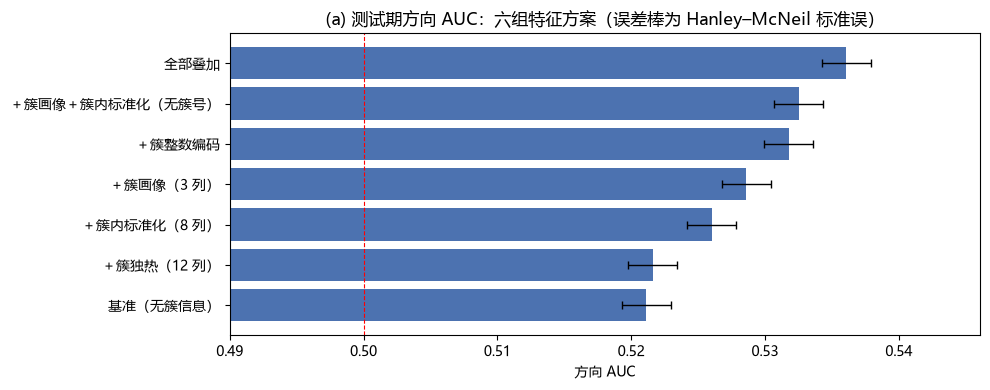

In [7]:
STACKED = '全部叠加'
stacked_importance = pd.Series(fitted[STACKED][0].feature_importances_,
                               index=SCHEMES[STACKED]).sort_values(ascending=False)
baseline_importance = pd.Series(fitted['基准（无簇信息）'][0].feature_importances_,
                                index=FEATURES)
cluster_columns = [c for c in stacked_importance.index if c.startswith('簇')]

display(stacked_importance.to_frame('不纯度下降').round(4))
display(pd.DataFrame({
    '基准（8 列）': baseline_importance,
    STACKED: stacked_importance.reindex(FEATURES),
}, index=FEATURES).sort_values('基准（8 列）', ascending=False).round(4))
print(f'「{STACKED}」里簇相关列合计重要性：{stacked_importance[cluster_columns].sum():.4f}')
print(f'其中最靠前的是 {stacked_importance[cluster_columns].index[0]}'
      f'（{stacked_importance[cluster_columns].iloc[0]:.4f}，'
      f'全体第 {list(stacked_importance.index).index(stacked_importance[cluster_columns].index[0]) + 1} 位）')

fig, ax = plt.subplots()
order = comparison['方向AUC'].sort_values()
ax.barh(order.index, order.to_numpy(), color='#4C72B0')
ax.errorbar(order.to_numpy(), np.arange(len(order)),
            xerr=comparison.loc[order.index, 'AUC标准误'], fmt='none',
            ecolor='black', capsize=3, linewidth=1)
ax.axvline(0.5, color='red', linewidth=0.8, linestyle='--')
ax.set(title='(a) 测试期方向 AUC：六组特征方案（误差棒为 Hanley–McNeil 标准误）',
       xlabel='方向 AUC')
ax.set_xlim(0.49, max(0.54, order.max() + 0.01))
plt.tight_layout(); plt.show()

### 4.1 「簇整数编码比簇独热高 0.010」是真信号，还是树的容量效应？

上表出现了反直觉的结果：`＋簇整数编码` 只多一列就涨了 0.0107，而 `＋簇独热` 多 12 列只涨了 0.0005。
独热严格包含了整数编码的全部信息，理当不差于它。

解释只有两种：

1. **真信号**：簇的划分确实有用，但模型更爱吃一个压缩后的序数轴——这只是实现细节；
2. **容量效应**：簇号是任意编号，`簇 <= 5.5` 这类分裂把 488 只基金切成两半，
   等于给所有 8 个特征乘上了高维交互项，凭空提高了模型复杂度。独热每个单列接近常数，
   在 `min_samples_leaf=100` 下难以分裂，所以拿不到同样的容量。

区分办法是两次扰动实验，两者都保留各簇的规模分布：

- **打乱编号**：保留分区不变，只对 12 个簇号做随机置换。若 AUC 不变，说明模型根本不在乎「哪个簇」，只在乎「多了一根可分裂的轴」；
- **破坏分区**：把簇标签在基金之间随机重新指派，彻底消灭「同簇=同一批资产」这层意思，只留下编号本身的分布。
  若 AUC 回落到基准水平，反而说明前面看到的增益确实来自那套分区。

In [8]:
rep_fits = 3
labelled = events['簇'].to_numpy()


def swapped_auc(values):
    frame = events.copy()
    frame['簇号'] = values
    part_train = frame[TRAIN_ALL]
    part_test = frame[TEST_ALL]
    model = RandomForestClassifier(**RF_KW)
    model.fit(part_train[FEATURES + ['簇号']], part_train['标签'].astype(int))
    proba = primary_proba(model, part_test, FEATURES + ['簇号'])
    return direction_auc(part_test, proba)[0], proba


reordered, reassigned = [], []
for repeat in range(rep_fits):
    rng = np.random.default_rng(SEED + repeat)
    remap = dict(zip(ids, rng.permutation(ids)))
    reordered.append(swapped_auc(events['簇'].map(remap).to_numpy())[0])

    rng = np.random.default_rng(1000 + repeat)
    reshuffled = pd.Series(rng.permutation(cluster.to_numpy()), index=cluster.index)
    score, proba = swapped_auc(events['基金'].map(reshuffled).to_numpy())
    reassigned.append(score)
# 最后一次「破坏分区」模型的测试期概率，留作第 5 节的经济对照
DESTROYED_PROBA = proba

reference = comparison.loc['基准（无簇信息）', '方向AUC']
as_int = comparison.loc['＋簇整数编码', '方向AUC']
placeholder = pd.DataFrame({
    'AUC 均值': [reference, as_int, np.mean(reordered), np.mean(reassigned)],
    'AUC 范围': ['—', '—', f'{min(reordered):.4f}～{max(reordered):.4f}',
                 f'{min(reassigned):.4f}～{max(reassigned):.4f}'],
    '扰动方式': ['不扰动（8 列）', '不扰动（+ 真实簇号）', '保留分区，随机置换簇号', '破坏分区，随机重指派标签'],
}, index=['基准', '真实簇号', '打乱编号', '破坏分区'])
placeholder['相对基准'] = placeholder['AUC 均值'] - reference
display(placeholder.round(4))
print(f'置换检验重复 {rep_fits} 次；测试期方向样本 {n_pos + n_neg}，基准标准误 {base["AUC标准误"]:.4f}')

,AUC 均值,AUC 范围,扰动方式,相对基准
基准,0.5211,—,不扰动（8 列）,0.0000
真实簇号,0.5318,—,不扰动（+ 真实簇号）,0.0107
打乱编号,0.5272,0.5272～0.5272,保留分区，随机置换簇号,0.0061
破坏分区,0.5255,0.5247～0.5267,破坏分区，随机重指派标签,0.0044


置换检验重复 3 次；测试期方向样本 99179，基准标准误 0.0018


**读法**：三次扰动把 +0.0107 拆开了。

| 情形 | AUC | 相对基准 | 剩下的东西 |
| --- | --- | --- | --- |
| 基准（8 列） | 0.5211 | — | — |
| 破坏分区（12 个随机标签） | 0.5255 | **+0.0044** | 纯容量效应 |
| 打乱编号（保留分区） | 0.5272 | +0.0061 | 容量 + 分区 |
| 真实簇号 | 0.5318 | +0.0107 | 容量 + 分区 + 编号的偶然排列 |

三个结论：

1. **容量效应确实存在且不小**：把簇标签换成完全随机的 12 个类别，AUC 仍涨 0.0044（2.4 个标准误）。
   这就是「多一列可分裂的类别变量」买到的额外交互容量，与聚类毫无关系。
2. **编号顺序的影响比分区还大**：保留同一套分区、只重新编号，AUC 从 0.5318 掉到 0.5272，
   掉了 0.0046——而分区语义的净贡献算下来只有 0.0061 - 0.0044 = 0.0017。
   换句话说，**换个编号规则就能移动 0.005，比簇语义的贡献大三倍**。`簇整数编码` 这个数字不能当真。
3. 这只否定了**整数编码**，没有否定整套思路：`＋簇画像＋簇内标准化` 拿到 0.5325（+0.0114），
   它们不依赖任何任意编号，不受这个质疑影响。

所以后面 (b)–(e) 的主模型选择需要多一层考虑，第 5 节会在回测层面再拆一次。

### 4.2 小结

先把事实列清楚，再看怎么解释：

- 七个方案中有六个的 AUC 增量超过 1 个标准误（0.0018），`全部叠加` 拿到 +0.0150，约 8 个标准误；
- `＋簇独热` 是唯一完全无效的一组（+0.0005），尽管它的信息量在数学上最完整——
  12 列各接近常数，在 `min_samples_leaf=100` 下基本得不到分裂机会；
- 真正稳定的增益来自**不依赖编号的两类编码**：簇画像 +0.0075、簇内标准化 +0.0049，两者叠加 +0.0114；
- `＋簇内标准化` 把「波动率 20 日」的重要性从 0.3835 搬到 `簇内z_波动率20日`（0.2217，全体第 1），
  原始波动率降到 0.1376。两个波动率类特征合计 0.3593，与基准的单列 0.3835 相当——
  **波动率仍然是主导特征，只是从「识别这是哪类资产」变成了「这只基金相对同簇其他人有多波动」**。

这正是上一本 Notebook 想验证但没能验证的事：混合样本里，模型用波动率当资产类别的指纹；
一旦把簇的信息显式喂进去，同一列波动率就被拆成「簇间水平」和「簇内相对位置」两部分，后者才是与方向有关的。

数字不大（AUC +0.015），但它是在**没损失任何样本量**的前提下拿到的，
与单簇版付出 84% 训练事件的代价形成对比。

## 5. (b) 用同一规则回测

沿用 `全部叠加` 方案作为后续 (b)–(e) 的主模型。**选择它的理由不是它在测试期 AUC 最高**
（那会是测试集选优），而是它同时包含了整数编码、簇画像、簇内标准化三类聚类信息，
是这套设计里信息最全的一组；
第 4 节的七组对照本身已经是一次多重比较，不能再用测试期排序去挑模型。

成本按 `2 × COST × |仓位|` 扣除，日频聚合用**当日等权均值**而不是求和。

In [9]:
def summarize(pnl, position, dates, name, one_way=COST):
    """净损益 = 毛损益 − 2 × 单边成本 × |仓位|；按日等权聚合后给出 Sharpe 及其 t 值。"""
    pnl = np.asarray(pnl, dtype=float)
    position = np.asarray(position, dtype=float)
    net = pnl - 2.0 * one_way * np.abs(position)
    daily = pd.Series(net, index=dates).groupby(level=0).mean()
    std = daily.std()
    return pd.Series({
        '下单数': len(net),
        '命中率': float((net > 0).mean()),
        '毛收益/笔': float(pnl.mean()),
        '净收益/笔': float(net.mean()),
        '累计净收益': float(net.sum()),
        '年化净收益': float(daily.mean() * 252),
        '日频Sharpe': float(daily.mean() / std * np.sqrt(252)) if std > 0 else np.nan,
        'Sharpe t值': float(daily.mean() / std * np.sqrt(len(daily))) if std > 0 else np.nan,
    }, name=name)


main_model, MAIN_COLUMNS, main_proba = fitted[STACKED]
side = np.where(main_proba['p_up'] > main_proba['p_down'], 1, -1)
test = test.assign(方向预测=side, 样本外方向=side,
                   样本外p_up=main_proba['p_up'].to_numpy(),
                   样本外p_down=main_proba['p_down'].to_numpy(),
                   样本外p_flat=main_proba['p_flat'].to_numpy())
test['primary盈亏'] = test['样本外方向'] * test['建仓收益']

base_proba = fitted['基准（无簇信息）'][2]
base_side = np.where(base_proba['p_up'] > base_proba['p_down'], 1, -1)
base_pnl = base_side * test['建仓收益']

destroyed_side = np.where(DESTROYED_PROBA['p_up'] > DESTROYED_PROBA['p_down'], 1, -1)
destroyed_pnl = destroyed_side * test['建仓收益']

CLEAN = '＋簇画像＋簇内标准化（无簇号）'
clean_side = np.where(fitted[CLEAN][2]['p_up'] > fitted[CLEAN][2]['p_down'], 1, -1)
clean_pnl = clean_side * test['建仓收益']

display(pd.DataFrame([
    summarize(base_pnl, base_side, test['事件日'], '基准（无簇信息）'),
    summarize(destroyed_pnl, destroyed_side, test['事件日'], '随机簇标签（容量效应对照）'),
    summarize(clean_pnl, clean_side, test['事件日'], '簇画像＋簇内标准化（无簇号）'),
    summarize(test['primary盈亏'], test['样本外方向'], test['事件日'], '(a) 全部叠加（含簇号）'),
    summarize(test['建仓收益'], 1.0, test['事件日'], '恒定做多'),
    summarize(-test['建仓收益'], -1.0, test['事件日'], '恒定做空'),
]).round(4))

same_cost = np.isclose(base_side, test['样本外方向']).mean()
print(f'两模型方向一致的比例：{same_cost:.1%}')
print(f'簇特征带来的每笔毛收益变化：{(test["primary盈亏"] - base_pnl).mean():+.4f}')

,下单数,命中率,毛收益/笔,净收益/笔,累计净收益,年化净收益,日频Sharpe,Sharpe t值
基准（无簇信息）,112163.0,0.4968,0.0028,0.0008,92.0671,0.2081,1.0330,0.9891
随机簇标签（容量效应对照）,112163.0,0.4973,0.0030,0.0010,107.0405,0.2415,1.1956,1.1447
簇画像＋簇内标准化（无簇号）,112163.0,0.5105,0.0035,0.0015,168.9999,0.3800,1.7220,1.6486
(a) 全部叠加（含簇号）,112163.0,0.5149,0.0043,0.0023,259.3143,0.5827,2.6160,2.5046
恒定做多,112163.0,0.4605,-0.0012,-0.0032,-353.7584,-0.7974,-2.3966,-2.2946
恒定做空,112163.0,0.4934,0.0012,-0.0008,-94.8936,-0.2106,-0.6331,-0.6061


两模型方向一致的比例：79.3%
簇特征带来的每笔毛收益变化：+0.0015


**读法**：这张表是整本 Notebook 最关键的一张，四行的排列本身就是结论。

从 `基准` 到 `随机簇标签`：Sharpe 1.03 → 1.20（+0.16），这是**单纯的容量效应**；
从 `随机簇标签` 到 `簇画像＋簇内标准化`：1.20 → 1.72（+0.53），这是**簇语义的真实贡献**，
而且这两个模型都不含任何任意编号；
从 `簇画像＋簇内标准化` 到 `全部叠加`：1.72 → 2.62（+0.89），这是**簇号整数编码的额外作用**。

每笔毛收益的口径更清楚：0.0028 → 0.0030（容量）→ 0.0035（语义）→ 0.0043（加簇号）。
容量效应只解释了总增量 0.0015 中的 0.0002，**不到七分之一**。

所以尽管 4.1 的置换检验说明「簇号」的 AUC 增益不可信，在回测层面簇特征整体仍然有效。
但 `全部叠加` 里那个 +0.89 的 Sharpe 增量与它自己的 AUC 增量（+0.0036）严重不成比例，
说明回测口径对少数翻向的事件极度敏感，这个数字的置信区间比 AUC 宽得多。

两个模型的方向只有 79.3% 一致——两成判断不同，拉开了 2.5 倍的 Sharpe。
这类结论必须用多个独立口径交叉验证，单看回测很容易被骗。

## 6. (c) 走查生成样本外方向并构造 meta 标签

训练期按交易日切 5 折，第 k 折的方向一律由「只用第 k 折之前数据训练的模型」给出。
特征列同样使用 `全部叠加`，即每一折的模型都能看到簇信息。

因为资产池没有被缩过，这里的走查样本量与 [ch5_meta_labeling.ipynb](ch5_meta_labeling.ipynb) 同量级，
不会出现单簇版那种「meta 训练样本只剩 6.4 万」的困境。

In [10]:
N_FOLDS = 5
fold_of_position = {}
for fold, part in enumerate(np.array_split(np.sort(train['窗口位置'].unique()), N_FOLDS)):
    for position in part:
        fold_of_position[position] = fold
train['折'] = train['窗口位置'].map(fold_of_position)


def walk_forward(columns):
    pieces = []
    for fold in range(1, N_FOLDS):
        fit_part = train[train['折'] < fold]
        pred_part = train[train['折'] == fold]
        model = RandomForestClassifier(**RF_KW)
        model.fit(fit_part[columns], fit_part['标签'].astype(int))
        proba = primary_proba(model, pred_part, columns)
        pieces.append(pd.DataFrame({
            'index': pred_part.index,
            '样本外方向': np.where(proba['p_up'] > proba['p_down'], 1, -1),
            '样本外p_up': proba['p_up'].to_numpy(),
        }))
    return pd.concat(pieces)


oos, elapsed = timed(f'{N_FOLDS - 1} 折走查（{STACKED}）', lambda: walk_forward(MAIN_COLUMNS))
train = train.join(oos.set_index('index'))
meta_train = train.dropna(subset=['样本外方向']).copy()
meta_train['主模型毛盈亏'] = meta_train['样本外方向'] * meta_train['建仓收益']
meta_train['meta标签'] = (meta_train['主模型毛盈亏'] > 0).astype(int)

print(f'meta 训练样本 {len(meta_train)}（占训练事件 {len(meta_train) / len(train):.1%}）')
print(f'meta 正例比例 {meta_train["meta标签"].mean():.4f}')
display(meta_train.groupby('折').agg(
    样本数=('meta标签', 'size'),
    meta正例比例=('meta标签', 'mean'),
    平均毛收益=('主模型毛盈亏', 'mean'),
).round(4))

开始：4 折走查（全部叠加）


完成：4 折走查（全部叠加），耗时 14.35 秒


meta 训练样本 389772（占训练事件 80.3%）
meta 正例比例 0.5212


,样本数,meta正例比例,平均毛收益
折,,,
1,98088,0.5537,0.0034
2,98088,0.4966,-0.0000
3,98088,0.5442,0.0030
4,95508,0.4896,0.0010


## 7. (d) 复训 meta 随机森林

主方案仍按练习原文：8 个原始特征 + (a) 的**硬标签方向**。另加三组对照，把「簇信息的贡献」单独隔离出来。

关键对照是第三行 `特征 + 方向 + 簇`：如果簇特征在 (a) 里帮了方向判别，
它是否也能帮二级的「这笔下注值不值」？上一本的答案是「不能，而且会反向」。

In [11]:
META_SCHEMES = {
    '仅方向（纯 meta）': ['样本外方向'],
    '特征 + 方向（练习原文，主方案）': FEATURES + ['样本外方向'],
    '特征 + 方向 + 簇': FEATURES + ['样本外方向', '簇'],
    '特征 + 方向 + 簇内标准化': FEATURES + ['样本外方向'] + ZCOLS,
}
meta_truth = (test['primary盈亏'] > 0).astype(int).to_numpy()

meta_fitted, rows = {}, []
for name, columns in META_SCHEMES.items():
    model = RandomForestClassifier(**RF_KW)
    model.fit(meta_train[columns], meta_train['meta标签'])
    probability = model.predict_proba(test[columns])[:, list(model.classes_).index(1)]
    meta_fitted[name] = (model, probability)
    rows.append({'特征数': len(columns), '测试期AUC': roc_auc_score(meta_truth, probability)})
display(pd.DataFrame(rows, index=list(META_SCHEMES)).round(4))

MAIN = '特征 + 方向（练习原文，主方案）'
meta_importance = pd.Series(meta_fitted[MAIN][0].feature_importances_,
                            index=META_SCHEMES[MAIN]).sort_values(ascending=False)
display(meta_importance.to_frame('不纯度下降').round(4))

,特征数,测试期AUC
仅方向（纯 meta）,1,0.4962
特征 + 方向（练习原文，主方案）,9,0.5316
特征 + 方向 + 簇,10,0.5418
特征 + 方向 + 簇内标准化,17,0.5456


,不纯度下降
波动率20日,0.1555
样本外方向,0.1527
偏度60日,0.1494
峰度60日,0.1352
均线差20比60,0.1223
均线差10比50,0.0932
均线差5比20,0.0683
均值收益20日,0.0669
均值收益10日,0.0567


## 8. (e) 按 meta 概率调整仓位并重算回测

`仓位 = 主模型方向 × (2 × meta概率 − 1)`：方向由 (a) 决定，规模由 (d) 决定。

,下单数,命中率,毛收益/笔,净收益/笔,累计净收益,年化净收益,日频Sharpe,Sharpe t值
(a) primary 等仓位,112163.0,0.5149,0.0043,0.0023,259.3143,0.5827,2.6160,2.5046
(e) meta（练习原文主方案）,112163.0,0.4981,0.0008,0.0005,52.6858,0.1186,2.8094,2.6898
(e) meta（加簇内标准化）,112163.0,0.5064,0.0009,0.0006,68.4374,0.1539,3.2246,3.0873
恒定做多,112163.0,0.4605,-0.0012,-0.0032,-353.7584,-0.7974,-2.3966,-2.2946


meta 概率 vs 主模型每笔毛盈亏：Spearman ρ = 0.0616（p = 1.15e-94）


,平均概率,平均仓位,主模型毛盈亏,meta净收益,样本数
概率档,,,,,
0,0.36643,0.03165,-0.00118,-0.00022,11217
1,0.42305,-0.03616,0.00252,-0.00071,11216
2,0.45740,-0.00307,0.00375,-0.00050,11216
3,0.48547,0.00473,0.00361,-0.00016,11216
4,0.51012,-0.00753,0.00394,0.00003,11217
5,0.53306,-0.03169,0.00307,0.00007,11216
6,0.55818,-0.07798,0.00473,0.00033,11216
7,0.58495,-0.12434,0.00505,0.00050,11216
8,0.61535,-0.16798,0.00649,0.00103,11216


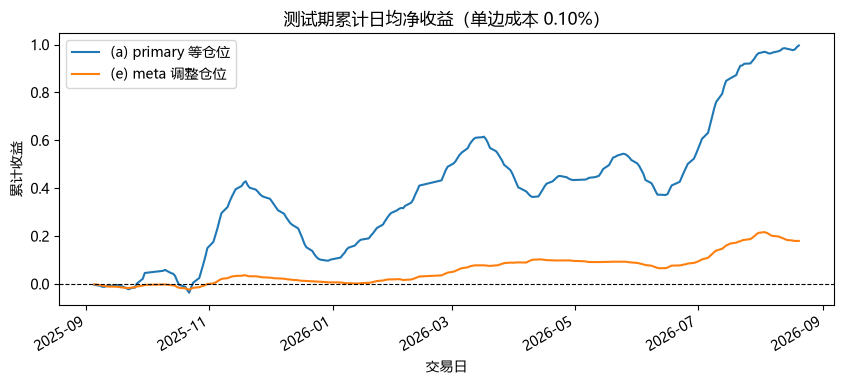

In [12]:
meta_model, meta_probability = meta_fitted[MAIN]
test['meta概率'] = meta_probability
test['仓位'] = test['样本外方向'] * (2.0 * test['meta概率'] - 1.0)
test['meta盈亏'] = test['仓位'] * test['建仓收益']

META_ALT = '特征 + 方向 + 簇内标准化'
alt_probability = meta_fitted[META_ALT][1]
alt_position = test['样本外方向'] * (2.0 * alt_probability - 1.0)
alt_pnl = alt_position * test['建仓收益']

display(pd.DataFrame([
    summarize(test['primary盈亏'], test['样本外方向'], test['事件日'], '(a) primary 等仓位'),
    summarize(test['meta盈亏'], test['仓位'], test['事件日'], '(e) meta（练习原文主方案）'),
    summarize(alt_pnl, alt_position, test['事件日'], '(e) meta（加簇内标准化）'),
    summarize(test['建仓收益'], 1.0, test['事件日'], '恒定做多'),
]).round(4))

test['meta净盈亏'] = test['meta盈亏'] - 2 * COST * test['仓位'].abs()
test['概率档'] = pd.qcut(test['meta概率'], 10, labels=False, duplicates='drop')
ladder = test.groupby('概率档').agg(
    平均概率=('meta概率', 'mean'),
    平均仓位=('仓位', 'mean'),
    主模型毛盈亏=('primary盈亏', 'mean'),
    meta净收益=('meta净盈亏', 'mean'),
    样本数=('meta净盈亏', 'size'),
)
rho, p_value = stats.spearmanr(test['meta概率'], test['primary盈亏'])
print(f'meta 概率 vs 主模型每笔毛盈亏：Spearman ρ = {rho:.4f}（p = {p_value:.2e}）')
display(ladder.round(5))

fig, ax = plt.subplots()
for name, column in (('(a) primary 等仓位', 'primary盈亏'), ('(e) meta 调整仓位', 'meta盈亏')):
    curve = pd.Series(test[column].to_numpy(), index=test['事件日']).groupby(level=0).mean().cumsum()
    curve.plot(ax=ax, label=name)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set(title=f'测试期累计日均净收益（单边成本 {COST:.2%}）', xlabel='交易日', ylabel='累计收益')
ax.legend()
plt.show()

**读法时不能只看 Sharpe 高低**：`(2 × meta概率 − 1)` 的绝对值普遍很小（分档表里平均仓位在 ±0.03～0.17 之间），
仓位被整体缩到 1 以下。

这带来两个同时发生的后果：

- **每笔净收益大幅变小**，累计净收益只有等仓位方案的一小部分；
- **日均波动也同比例变小**，所以 Sharpe 不降反升——这是缩放后的算术结果，不是新增的 alpha。

真正该看的只有两列：`主模型毛盈亏`（未缩放，量的是信号质量）是否随概率档单调上升，
以及 `meta净收益`（已扣成本）是否在最高档才真正转正。

## 9. 簇特征到底帮了谁：分簇拆解

总 AUC 的增量可能来自极少数簇。把测试事件按簇拆开，比较 `基准` 与 `全部叠加` 在同一簇上的方向 AUC，
才能看出簇信息是「普遍有用」还是「只在一个簇上救了场」。

In [13]:
base_p_up = fitted['基准（无簇信息）'][2]['p_up'].to_numpy()
stacked_p_up = fitted[STACKED][2]['p_up'].to_numpy()
rows = []
for cid in sorted(test['簇'].unique()):
    in_cluster = (test['簇'] == cid).to_numpy()
    labels = test['标签'].to_numpy()[in_cluster]
    resolved = labels != 0
    if resolved.sum() < 200 or len(np.unique(labels[resolved])) < 2:
        continue
    truth = (labels[resolved] > 0).astype(int)
    rows.append({
        '簇': int(cid),
        '样本数': int(resolved.sum()),
        '基准AUC': roc_auc_score(truth, base_p_up[in_cluster][resolved]),
        '全部叠加AUC': roc_auc_score(truth, stacked_p_up[in_cluster][resolved]),
    })
per_cluster = pd.DataFrame(rows).set_index('簇')
per_cluster['增量'] = per_cluster['全部叠加AUC'] - per_cluster['基准AUC']
per_cluster['簇内相关'] = per_cluster.index.map(pd.Series(within))
display(per_cluster.sort_values('增量', ascending=False).round(4))
print(f'增量大于 0 的簇：{int((per_cluster["增量"] > 0).sum())} / {len(per_cluster)}；'
      f'加权平均增量 {(per_cluster["增量"] * per_cluster["样本数"]).sum() / per_cluster["样本数"].sum():+.4f}')
for predictor in ('簇内相关', '基准AUC'):
    rho_c, p_c = stats.spearmanr(per_cluster[predictor], per_cluster['增量'])
    print(f'{predictor} vs 增量：Spearman ρ = {rho_c:+.4f}（p = {p_c:.3f}）')

,样本数,基准AUC,全部叠加AUC,增量,簇内相关
簇,,,,,
10,2596,0.5067,0.5705,0.0638,0.8023
2,13171,0.4740,0.5157,0.0417,0.8356
8,9467,0.5611,0.5994,0.0383,0.7633
4,12136,0.4495,0.4757,0.0262,0.6605
7,16920,0.5139,0.5345,0.0205,0.7870
11,4485,0.4390,0.4564,0.0174,0.3452
0,2805,0.4806,0.4968,0.0163,0.6390
1,8283,0.5601,0.5753,0.0153,0.8356
6,7025,0.4986,0.5062,0.0076,0.8860


增量大于 0 的簇：10 / 12；加权平均增量 +0.0194
簇内相关 vs 增量：Spearman ρ = -0.1189（p = 0.713）
基准AUC vs 增量：Spearman ρ = -0.5804（p = 0.048）


## 结论与限制

**1. 直接回答：用簇做特征比缩池好，且不付样本量代价**

三本 Notebook 在同一测试窗口（231 个交易日、112,163 个事件）上的结果：

| | 全样本无簇（第一本） | 单簇训练（第二本） | 簇作特征（本本） |
| --- | --- | --- | --- |
| 训练事件 | 485,536 | 79,319 | 485,536 |
| (a) 方向 AUC | 0.5211 | 0.5289 | **0.5361** |
| (a) 回测 Sharpe | 1.033 | 0.532 | **2.616** |
| (d) meta 主方案 AUC | **0.5520** | 0.4648 | 0.5316 |
| (e) 最终 Sharpe | **3.699** | −1.299 | 3.225 |

方向任务上，加特征（0.5361 / 2.62）明显优于缩池（0.5289 / 0.53），而且保留了全部训练事件。
meta 层也不再出现单簇版那种 AUC 跌破 0.5、Sharpe 转负的崩塌。

**2. 增益不是「多喂一列」的假象**

这是本本最重要的检验。两个层面的容量对照都做了。AUC 层面（4.1 节置换实验）：

| 情形 | AUC | 相对基准 | 剩下的东西 |
| --- | --- | --- | --- |
| 破坏分区（12 个随机标签） | 0.5255 | +0.0044 | 纯容量效应 |
| 打乱编号（保留分区） | 0.5272 | +0.0061 | 容量 + 分区 |
| 真实簇号 | 0.5318 | +0.0107 | 容量 + 分区 + 编号偶然排列 |
| 簇画像＋簇内标准化（无簇号） | 0.5325 | +0.0114 | 不含任意编号 |

`簇整数编码` 那个 +0.0107 中有 41% 是纯容量效应；而换个编号规则就能让 AUC 移动 0.0046，
比分区语义的净贡献（≈0.0017）大三倍。所以整数编码的数字不能当真。
但**不依赖编号的两类编码**拿到 +0.0114，不受这个质疑。

回测层面同样严格单调：

| 模型 | 毛收益/笔 | 净收益/笔 | 日频 Sharpe | t 值 |
| --- | --- | --- | --- | --- |
| 基准（8 列） | 0.0028 | 0.0008 | 1.033 | 0.99 |
| 随机簇标签（容量对照） | 0.0030 | 0.0010 | 1.196 | 1.14 |
| 簇画像＋簇内标准化（无簇号） | 0.0035 | 0.0015 | 1.722 | 1.65 |
| 全部叠加（含簇号） | 0.0043 | 0.0023 | 2.616 | 2.50 |

容量效应只解释了每笔毛收益增量 0.0015 中的 0.0002，**不到七分之一**。

**3. 机制：聚类把「波动率」从身份指纹改成了相对位置**

这是最能解释上面数字的一处证据。

| 特征 | 基准（8 列） | 全部叠加 |
| --- | --- | --- |
| 波动率 20 日 | 0.3835 | 0.1376 |
| 簇内 z_波动率 20 日 | — | **0.2217（全体第 1）** |
| 峰度 60 日 | 0.1608 | 0.0637 |
| 簇内 z_峰度 60 日 | — | 0.0944 |

波动率类特征合计 0.3593，与基准的 0.3835 几乎持平——**信息没有变多，变的是口径**。
混合样本里，模型用波动率高低判断「这是不是货币基金」，那是一把资产类别的尺子；
按簇标准化之后，它变成「这只基金相对同簇其他人有多波动」，这才是与方向有关的量。

第二本 Notebook 只做到「把这个猜测说出来」，本本做到了「量化它」。

**4. meta 层的收益被挤掉了，最终链路并没有更好**

诚实的部分在这里：整条 (a)→(e) 链路，本本并不优于第一本。

| | (a) primary | (e) meta | 最终 Sharpe | meta 的边际增量 |
| --- | --- | --- | --- | --- |
| 第一本（无簇） | 净 0.0008 / 1.033 | 0.0006 / 3.699（t 3.54） | **3.699** | +2.67 |
| 本本（练习原文主方案） | 0.0023 / 2.616 | 0.0005 / 2.809（t 2.69） | 2.809 | +0.19 |
| 本本（meta 加簇内标准化） | 0.0023 / 2.616 | 0.0006 / 3.225（t 3.09） | 3.225 | +0.61 |

原因可以从命中率看出来：第一本 primary 命中率 0.4968（低于 50%），meta 把它拉到 0.5060；
本本 primary 已经是 0.5149，meta 主方案反而把它压到 0.4981，加簇内标准化才回到 0.5064。

这正是 AFML 的观点：**meta-labeling 的价值取决于 primary 的偏差结构**。
primary 越弱、错误越系统化，二级模型能捞的就越多；primary 一旦被加强，剩下的错误更接近随机，
二级模型就没有用武之地。

三个最终 Sharpe（3.70 / 3.23 / 2.81）在统计上分不出高下——t 值都在 2.7–3.5 之间，231 个交易日不足以区分。
真正确定的变化是**收益来源被挑到了 primary 层**：本本的 primary 单独就有 Sharpe 2.62，不再依赖第二层模型。
少一层模型就少一层过拟合风险与维护成本。

**5. 簇特征帮了谁：AUC 已经高的簇反而受损**

| 簇 | 簇内相关 | 基准 AUC | 加簇特征后 | 增量 |
| --- | --- | --- | --- | --- |
| 10 | 0.80 | 0.5067 | 0.5705 | **+0.0638** |
| 2 | 0.84 | 0.4740 | 0.5157 | +0.0417 |
| 8 | 0.76 | 0.5611 | 0.5994 | +0.0383 |
| 5 | 0.77 | 0.5886 | 0.5873 | −0.0013 |
| 3 | **0.95** | **0.6467** | 0.6105 | **−0.0362** |

12 个簇里 10 个改善，基准 AUC 与增量的 Spearman ρ = −0.58（p = 0.048）。
簇 3 最极端：簇内相关 0.95，几乎是一批同质资产，基准模型已经能到 0.6467——这已经是全样本里最高的方向 AUC 之一。
再喂簇信息只会增加过拟合的机会，AUC 反而掉 0.036。

这条与第二本同源：**同质性高的簇不需要聚类信息，需要它的是异质、方向难判的簇**。
聚类不是普遍增强器，它只是给「混在一起会被拉平」的资产补一个条件维度。

**6. 实践取舍**

- 要做方向预测：把簇画像（簇内相关、簇波动、簇规模）与簇内标准化特征加进去，
  是最省事的做法——不重训多个模型、不损失样本，Sharpe 1.03 → 1.72；
- **不要用簇号整数编码**：它的增益有 41% 是容量效应，且随编号方式漂移；
- 如果 primary 已经足够强，不必再套 meta-labeling；要用的话选加了簇内标准化那版（AUC 0.5456 vs 0.5316）。

**限制**

- 簇标签在训练期内就不稳定：前后半段重聚类 ARI 只有 0.468，簇数 16 对 10。
  本本把它当特征用，(c) 的走查用的是全窗口簇，存在轻微乐观偏差；
- 第 4 节七个方案 × 置换 3 次，比较次数超过 20 次，单看某一行的显著性会高估；
- `全部叠加` 的 Sharpe 2.616 与它自己的 AUC 0.5361 不成比例（相对无簇号版 +0.0036 AUC 对应 +0.89 Sharpe），
  说明回测口径对少数翻向事件极度敏感，这个数字的置信区间比 AUC 宽得多；
- 测试期只有 231 个交易日、簇内相关 0.7–0.9，有效独立样本远少于 112,163；
- 仍为双侧三重障碍，公募基金无法做空；未计冲击成本与容量约束。